# Deep Learning Lab_USN
## Self Learning Lab Program 1 — Continuous Evaluation

### Aim
To demonstrate batch, stochastic, and mini-batch gradient descent; compare momentum-based and adaptive optimizers using constant and scheduled learning rates; investigate overfitting and regularization; apply early stopping; and compare plain and residual multilayer perceptrons.

### Datasets
- Experiment 1: Synthetic linear-regression dataset.
- Experiments 2–5: Fashion-MNIST dataset.

### Software and Libraries
Python, PyTorch, Torchvision, NumPy, Pandas, Matplotlib, and Jupyter Notebook.

### Methodology
Each experiment is conducted separately, and its results are analyzed using numerical metrics, tables, and graphs.

In [1]:
%pip install -q torch torchvision numpy matplotlib pandas scikit-learn

In [2]:
import copy
import random
from pathlib import Path

# Enable inline plotting
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

from IPython.display import display

# Input / Data directories (No output directories needed)
ROOT = Path.cwd()

# Reproducibility
def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def device_name():
    return torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

print("PyTorch version:", torch.__version__)
print("Device:", device_name())

PyTorch version: 2.11.0+cpu
Device: cpu


## Experiment 1 — Gradient Descent Methods

### Aim
To compare batch gradient descent, stochastic gradient descent, and mini-batch gradient descent on a synthetic regression dataset.

### Theory
- Batch gradient descent updates parameters using the entire training dataset.
- Stochastic gradient descent updates parameters using one training sample at a time.
- Mini-batch gradient descent updates parameters using a small group of training samples.

Mean squared error (MSE) is used to evaluate the regression model.

In [3]:
def run_gd(seed=42):
    seed_everything(seed)

    rng = np.random.default_rng(seed)

    # Generate a synthetic linear-regression dataset
    x = np.linspace(
        -2, 2, 120, dtype=np.float32
    ).reshape(-1, 1)

    y = (
        3.0 * x
        + 1.5
        + rng.normal(0, 0.35, size=x.shape).astype(np.float32)
    )

    def train(mode, epochs=60, lr=0.04, batch_size=16):
        w = np.array([[0.0]], dtype=np.float32)
        b = np.array([0.0], dtype=np.float32)

        losses = []
        n = len(x)

        for epoch in range(epochs):

            if mode == "batch":
                batches = [(x, y)]

            elif mode == "stochastic":
                order = rng.permutation(n)
                batches = [
                    (x[i:i+1], y[i:i+1])
                    for i in order
                ]

            else:
                order = rng.permutation(n)
                batches = [
                    (
                        x[i:i+batch_size],
                        y[i:i+batch_size]
                    )
                    for i in range(0, n, batch_size)
                ]

            for xb, yb in batches:
                pred = xb @ w + b
                error = pred - yb

                dw = (
                    2.0 / len(xb)
                ) * (xb.T @ error)

                db = 2.0 * error.mean(axis=0)

                w -= lr * dw
                b -= lr * db

            epoch_mse = np.mean((x @ w + b - y) ** 2)
            losses.append(float(epoch_mse))

        return w.item(), b.item(), losses

    results = []

    plt.figure(figsize=(8, 5))

    methods = [
        ("batch", 120),
        ("stochastic", 1),
        ("mini-batch", 16)
    ]

    for method, batch_size in methods:
        weight, bias, losses = train(
            method,
            batch_size=batch_size
        )

        results.append({
            "method": method,
            "final_weight": weight,
            "final_bias": bias,
            "final_mse": losses[-1]
        })

        plt.plot(losses, label=method)

    plt.xlabel("Epoch")
    plt.ylabel("Training MSE")
    plt.title("Batch vs Stochastic vs Mini-batch Gradient Descent")
    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()
    plt.close()

    results_df = pd.DataFrame(results)
    display(results_df)
    print("Experiment 1 completed.")
    return results_df

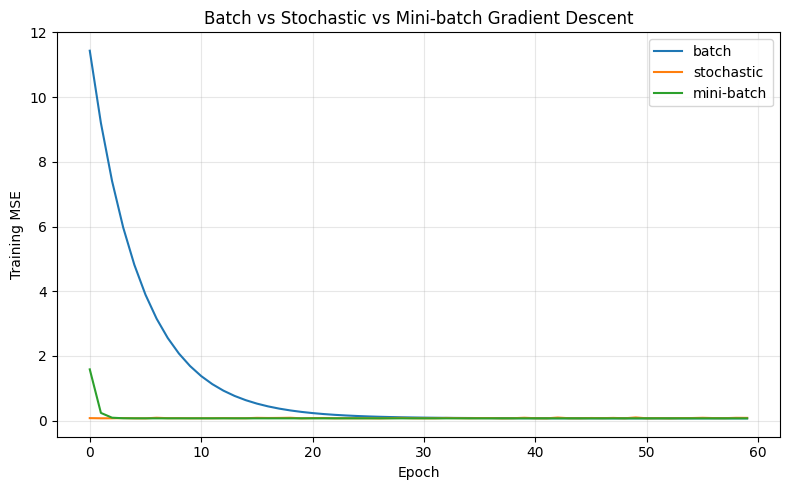

,method,final_weight,final_bias,final_mse
0,batch,2.967382,1.468924,0.073761
1,stochastic,3.050401,1.404594,0.087840
2,mini-batch,2.975499,1.483569,0.073707


Experiment 1 completed.


In [18]:
gd_results = run_gd(seed=42)

## Fashion-MNIST Dataset and MLP Architecture

Fashion-MNIST contains 28 × 28 grayscale clothing images from 10 classes. A subset is used to reduce training time.

The images are normalized before being passed to a multilayer perceptron. The input layer receives 784 pixel values, and the output layer produces scores for 10 classes.

In [5]:
class SmallMLP(nn.Module):
    def __init__(self, dropout=0.0, residual=False):
        super().__init__()

        self.residual = residual

        self.input = nn.Linear(28 * 28, 256)

        self.block1 = nn.Sequential(
            nn.Linear(256, 256),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        self.block2 = nn.Sequential(
            nn.Linear(256, 256),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        self.head = nn.Linear(256, 10)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = x.view(x.size(0), -1)
        x = self.relu(self.input(x))

        if self.residual:
            x = self.relu(x + self.block1(x))
            x = self.relu(x + self.block2(x))
        else:
            x = self.block1(x)
            x = self.block2(x)

        return self.head(x)


def get_loaders(
    train_limit=4000,
    test_limit=1000,
    batch_size=128,
    augment=False,
    seed=42
):
    # Augmentation is applied only to training images.
    if augment:
        train_transform = transforms.Compose([
            transforms.RandomCrop(28, padding=2),
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.ToTensor(),
            transforms.Normalize((0.5,), (0.5,))
        ])
    else:
        train_transform = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize((0.5,), (0.5,))
        ])

    eval_transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.5,), (0.5,))
    ])

    train_ds_aug = datasets.FashionMNIST(
        root=str(ROOT / "data"),
        train=True,
        download=True,
        transform=train_transform
    )

    train_ds_eval = datasets.FashionMNIST(
        root=str(ROOT / "data"),
        train=True,
        download=True,
        transform=eval_transform
    )

    test_ds = datasets.FashionMNIST(
        root=str(ROOT / "data"),
        train=False,
        download=True,
        transform=eval_transform
    )

    n_train = min(train_limit, len(train_ds_aug))
    n_test = min(test_limit, len(test_ds))

    generator = torch.Generator().manual_seed(seed)

    indices = torch.randperm(
        len(train_ds_aug),
        generator=generator
    )[:n_train].tolist()

    val_count = max(1, int(0.15 * n_train))

    val_indices = indices[:val_count]
    train_indices = indices[val_count:]

    train_set = Subset(train_ds_aug, train_indices)
    val_set = Subset(train_ds_eval, val_indices)
    test_set = Subset(test_ds, list(range(n_test)))

    train_loader = DataLoader(
        train_set,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0
    )

    val_loader = DataLoader(
        val_set,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0
    )

    test_loader = DataLoader(
        test_set,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0
    )

    return train_loader, val_loader, test_loader

In [6]:
def make_optimizer(
    name,
    model,
    lr,
    weight_decay=0.0
):
    if name == "sgd_momentum":
        return torch.optim.SGD(
            model.parameters(),
            lr=lr,
            momentum=0.9,
            weight_decay=weight_decay
        )

    if name == "rmsprop":
        return torch.optim.RMSprop(
            model.parameters(),
            lr=lr,
            weight_decay=weight_decay
        )

    if name == "adam":
        return torch.optim.Adam(
            model.parameters(),
            lr=lr,
            weight_decay=weight_decay
        )

    raise ValueError(f"Unknown optimizer: {name}")


def run_epoch(
    model,
    loader,
    criterion,
    device,
    optimizer=None
):
    training = optimizer is not None
    model.train(training)

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = criterion(logits, labels)

            if training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * labels.size(0)

        correct += (
            logits.argmax(dim=1) == labels
        ).sum().item()

        total += labels.size(0)

    return (
        total_loss / max(total, 1),
        correct / max(total, 1)
    )


def train_model(
    model,
    train_loader,
    val_loader,
    epochs,
    optimizer_name="adam",
    lr=0.001,
    schedule="constant",
    weight_decay=0.0,
    patience=None,
    seed=42
):
    seed_everything(seed)

    device = device_name()
    model = model.to(device)

    optimizer = make_optimizer(
        optimizer_name,
        model,
        lr,
        weight_decay
    )

    scheduler = None

    if schedule == "step":
        scheduler = torch.optim.lr_scheduler.StepLR(
            optimizer,
            step_size=max(1, epochs // 3),
            gamma=0.5
        )

    criterion = nn.CrossEntropyLoss()

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": [],
        "lr": []
    }

    best_val = float("inf")
    best_state = copy.deepcopy(model.state_dict())
    best_epoch = 0
    wait = 0

    for epoch in range(epochs):
        train_loss, train_acc = run_epoch(
            model,
            train_loader,
            criterion,
            device,
            optimizer
        )

        val_loss, val_acc = run_epoch(
            model,
            val_loader,
            criterion,
            device
        )

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["lr"].append(
            optimizer.param_groups[0]["lr"]
        )

        if val_loss < best_val:
            best_val = val_loss
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch + 1
            wait = 0
        else:
            wait += 1

        if scheduler is not None:
            scheduler.step()

        print(
            f"Epoch {epoch + 1:02d}/{epochs} | "
            f"train loss {train_loss:.4f} "
            f"acc {train_acc:.3f} | "
            f"val loss {val_loss:.4f} "
            f"acc {val_acc:.3f} | "
            f"lr {history['lr'][-1]:.5g}"
        )

        if patience is not None and wait >= patience:
            print(
                f"Early stopping at epoch {epoch + 1}; "
                f"best validation loss at epoch {best_epoch}."
            )
            break

    model.load_state_dict(best_state)

    history["best_epoch"] = best_epoch
    history["epochs_ran"] = len(history["train_loss"])

    return model, history


def plot_histories(histories, title, filename, metric="loss"):
    plt.figure(figsize=(9, 5))
    for label, history in histories.items():
        plt.plot(
            history[f"train_{metric}"],
            linestyle="--",
            label=f"{label} train"
        )
        plt.plot(
            history[f"val_{metric}"],
            label=f"{label} validation"
        )
    plt.xlabel("Epoch")
    plt.ylabel("Loss" if metric == "loss" else "Accuracy")
    plt.title(title)
    plt.legend(fontsize=8)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    plt.close()


def evaluate_test(model, loader):
    device = device_name()

    loss, accuracy = run_epoch(
        model,
        loader,
        nn.CrossEntropyLoss(),
        device
    )

    return loss, accuracy

## Experiment 2 — Optimizers and Learning Rates

### Aim
To compare SGD with momentum, RMSprop, and Adam using constant and step-decay learning rates.

### Methodology
The same MLP architecture and Fashion-MNIST training/validation subsets are used for all six configurations. Performance is measured using test loss and test accuracy.

In [7]:
def run_optimizers(
    epochs=5,
    train_limit=4000,
    test_limit=1000,
    seed=42
):
    train_loader, val_loader, test_loader = get_loaders(
        train_limit,
        test_limit,
        seed=seed
    )

    rows = []
    histories = {}

    configs = [
        ("sgd_momentum", "constant"),
        ("sgd_momentum", "step"),
        ("rmsprop", "constant"),
        ("rmsprop", "step"),
        ("adam", "constant"),
        ("adam", "step")
    ]

    for opt_name, sched in configs:
        label = f"{opt_name} + {sched}"

        print(f"\nRunning {label}")
        seed_everything(seed)

        model, history = train_model(
            SmallMLP(),
            train_loader,
            val_loader,
            epochs,
            optimizer_name=opt_name,
            lr=0.01 if opt_name != "adam" else 0.001,
            schedule=sched,
            seed=seed
        )

        test_loss, test_acc = evaluate_test(
            model,
            test_loader
        )

        histories[label] = history

        rows.append({
            "optimizer": opt_name,
            "lr_schedule": sched,
            "best_epoch": history["best_epoch"],
            "test_loss": test_loss,
            "test_accuracy": test_acc
        })

    plot_histories(
        histories,
        "Optimizer Comparison: Training and Validation Loss",
        "optimizer_loss.png",
        "loss"
    )

    df = pd.DataFrame(rows).sort_values(
        "test_accuracy",
        ascending=False
    )

    print("\nExperiment 2 completed.")
    display(df)

    return df


Running sgd_momentum + constant
Epoch 01/5 | train loss 2.2596 acc 0.257 | val loss 2.1682 acc 0.438 | lr 0.01
Epoch 02/5 | train loss 1.8176 acc 0.485 | val loss 1.2965 acc 0.560 | lr 0.01
Epoch 03/5 | train loss 1.0207 acc 0.629 | val loss 0.8830 acc 0.658 | lr 0.01
Epoch 04/5 | train loss 0.7787 acc 0.694 | val loss 0.7512 acc 0.717 | lr 0.01
Epoch 05/5 | train loss 0.7045 acc 0.724 | val loss 0.8066 acc 0.695 | lr 0.01

Running sgd_momentum + step
Epoch 01/5 | train loss 2.2596 acc 0.257 | val loss 2.1682 acc 0.438 | lr 0.01
Epoch 02/5 | train loss 2.0199 acc 0.477 | val loss 1.7635 acc 0.430 | lr 0.005
Epoch 03/5 | train loss 1.5906 acc 0.473 | val loss 1.4254 acc 0.542 | lr 0.0025
Epoch 04/5 | train loss 1.3419 acc 0.574 | val loss 1.2908 acc 0.577 | lr 0.00125
Epoch 05/5 | train loss 1.2422 acc 0.601 | val loss 1.2358 acc 0.593 | lr 0.000625

Running rmsprop + constant
Epoch 01/5 | train loss 143.7773 acc 0.295 | val loss 1.6369 acc 0.432 | lr 0.01
Epoch 02/5 | train loss 1.143

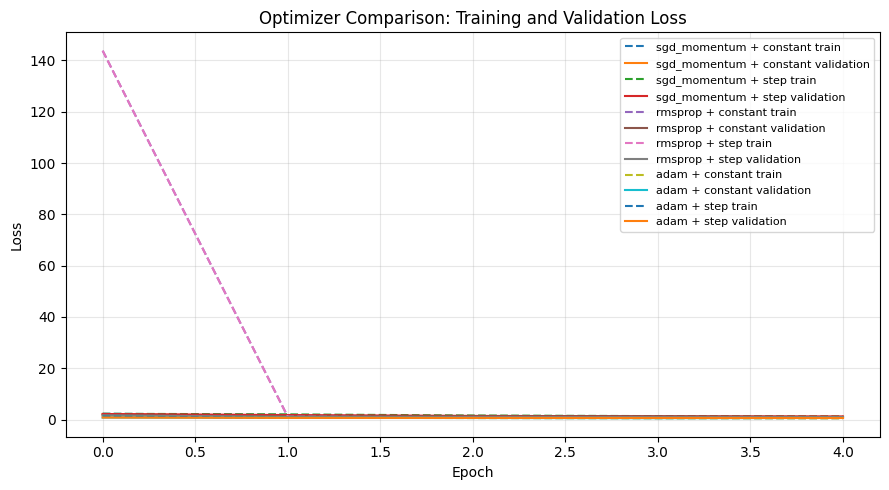


Experiment 2 completed.


,optimizer,lr_schedule,best_epoch,test_loss,test_accuracy
4,adam,constant,4,0.512812,0.817
5,adam,step,5,0.582743,0.778
0,sgd_momentum,constant,4,0.715513,0.719
2,rmsprop,constant,5,0.830421,0.683
3,rmsprop,step,5,0.876686,0.653
1,sgd_momentum,step,5,1.220402,0.581


In [8]:
optimizer_results = run_optimizers(
    epochs=5,
    train_limit=4000,
    test_limit=1000,
    seed=42
)

## Experiment 3 — Overfitting and Regularization

### Aim
To investigate overfitting and evaluate dropout, L2 regularization, and data augmentation.

### Configurations
1. Baseline MLP without additional regularization.
2. Dropout with probability 0.3.
3. L2 regularization using weight decay of 0.0001.
4. Data augmentation using random cropping and horizontal flipping.

Training accuracy, validation accuracy, test accuracy, and loss are compared.

In [9]:
def run_regularization(
    epochs=6,
    train_limit=3000,
    test_limit=1000,
    seed=42
):
    configs = [
        ("baseline", 0.0, 0.0, False),
        ("dropout_0.3", 0.3, 0.0, False),
        ("L2_weight_decay", 0.0, 1e-4, False),
        ("data_augmentation", 0.0, 0.0, True)
    ]

    rows = []
    histories = {}

    for label, dropout, wd, augment in configs:
        print(f"\nRunning {label}")

        train_loader, val_loader, test_loader = get_loaders(
            train_limit,
            test_limit,
            augment=augment,
            seed=seed
        )

        seed_everything(seed)

        model, history = train_model(
            SmallMLP(dropout=dropout),
            train_loader,
            val_loader,
            epochs,
            optimizer_name="adam",
            lr=0.001,
            weight_decay=wd,
            seed=seed
        )

        test_loss, test_acc = evaluate_test(
            model,
            test_loader
        )

        histories[label] = history

        rows.append({
            "configuration": label,
            "test_loss": test_loss,
            "test_accuracy": test_acc,
            "best_epoch": history["best_epoch"],
            "final_train_accuracy": history["train_acc"][-1],
            "final_validation_accuracy": history["val_acc"][-1]
        })

    plot_histories(
        histories,
        "Regularization Comparison: Loss",
        "regularization_loss.png",
        "loss"
    )

    plot_histories(
        histories,
        "Regularization Comparison: Accuracy",
        "regularization_accuracy.png",
        "acc"
    )

    df = pd.DataFrame(rows).sort_values(
        "test_accuracy",
        ascending=False
    )

    print("\nExperiment 3 completed.")
    display(df)

    return df


Running baseline
Epoch 01/6 | train loss 1.4035 acc 0.526 | val loss 0.8307 acc 0.678 | lr 0.001
Epoch 02/6 | train loss 0.7368 acc 0.723 | val loss 0.7155 acc 0.729 | lr 0.001
Epoch 03/6 | train loss 0.6355 acc 0.764 | val loss 0.6478 acc 0.747 | lr 0.001
Epoch 04/6 | train loss 0.5650 acc 0.780 | val loss 0.6196 acc 0.762 | lr 0.001
Epoch 05/6 | train loss 0.5094 acc 0.808 | val loss 0.5665 acc 0.773 | lr 0.001
Epoch 06/6 | train loss 0.4697 acc 0.825 | val loss 0.5382 acc 0.798 | lr 0.001

Running dropout_0.3
Epoch 01/6 | train loss 1.5501 acc 0.440 | val loss 0.8565 acc 0.653 | lr 0.001
Epoch 02/6 | train loss 0.8601 acc 0.662 | val loss 0.7138 acc 0.702 | lr 0.001
Epoch 03/6 | train loss 0.7020 acc 0.727 | val loss 0.6580 acc 0.727 | lr 0.001
Epoch 04/6 | train loss 0.6419 acc 0.751 | val loss 0.5927 acc 0.760 | lr 0.001
Epoch 05/6 | train loss 0.5849 acc 0.777 | val loss 0.6092 acc 0.767 | lr 0.001
Epoch 06/6 | train loss 0.5200 acc 0.802 | val loss 0.5484 acc 0.784 | lr 0.001



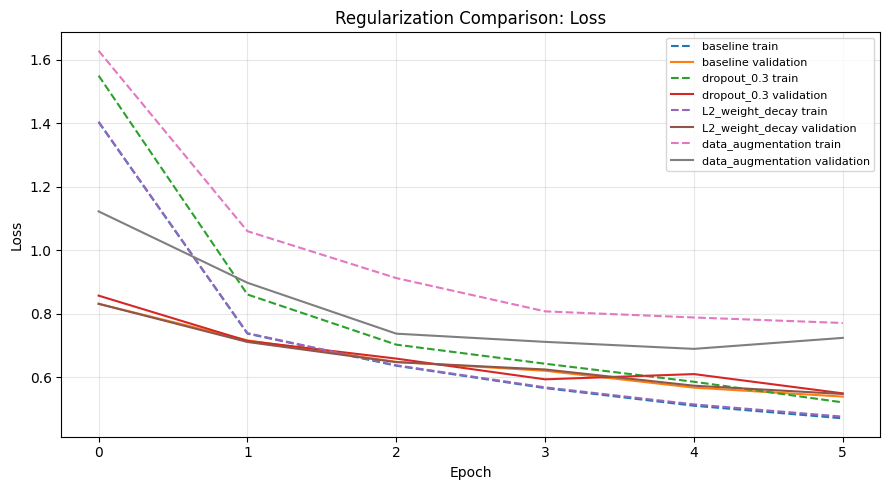

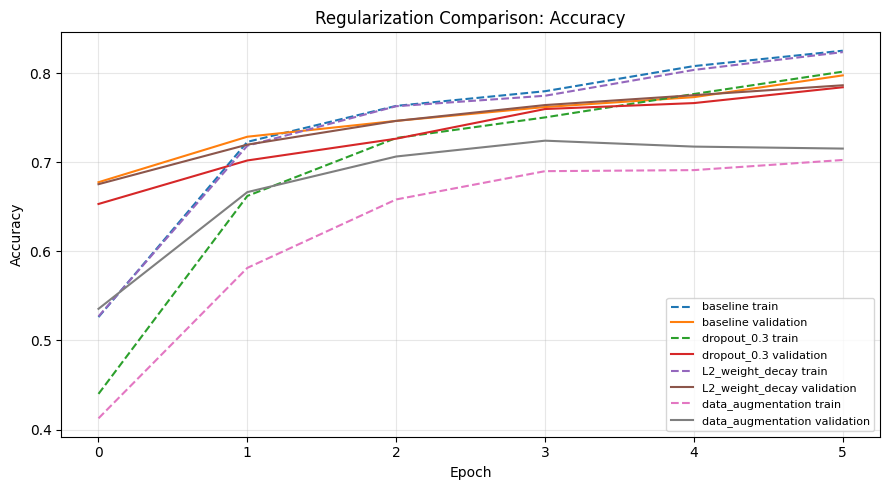


Experiment 3 completed.


,configuration,test_loss,test_accuracy,best_epoch,final_train_accuracy,final_validation_accuracy
1,dropout_0.3,0.528268,0.809,6,0.801961,0.784444
0,baseline,0.543540,0.806,6,0.825490,0.797778
2,L2_weight_decay,0.545825,0.801,6,0.823922,0.786667
3,data_augmentation,0.714623,0.717,5,0.702745,0.715556


In [10]:
regularization_results = run_regularization(
    epochs=6,
    train_limit=3000,
    test_limit=1000,
    seed=42
)

## Experiment 4 — Early Stopping

### Aim
To apply early stopping and prevent unnecessary training when validation loss stops improving.

### Methodology
The model is trained for a maximum of 15 epochs with a patience of three epochs. The model weights corresponding to the lowest validation loss are restored before test evaluation.

In [11]:
def run_early_stopping(
    epochs=15,
    train_limit=3000,
    test_limit=1000,
    seed=42
):
    train_loader, val_loader, test_loader = get_loaders(
        train_limit,
        test_limit,
        seed=seed
    )

    model, history = train_model(
        SmallMLP(),
        train_loader,
        val_loader,
        epochs,
        optimizer_name="adam",
        lr=0.001,
        patience=3,
        seed=seed
    )

    test_loss, test_acc = evaluate_test(
        model,
        test_loader
    )

    plot_histories(
        {"early_stopping": history},
        "Early Stopping: Training vs Validation Loss",
        "early_stopping_loss.png",
        "loss"
    )

    results = pd.DataFrame([{
        "epochs_requested": epochs,
        "epochs_ran": history["epochs_ran"],
        "best_epoch": history["best_epoch"],
        "test_loss": test_loss,
        "test_accuracy": test_acc
    }])

    print("\nExperiment 4 completed.")
    display(results)

    return results

Epoch 01/15 | train loss 1.4572 acc 0.518 | val loss 0.8332 acc 0.660 | lr 0.001
Epoch 02/15 | train loss 0.7669 acc 0.717 | val loss 0.6652 acc 0.738 | lr 0.001
Epoch 03/15 | train loss 0.6417 acc 0.756 | val loss 0.6294 acc 0.744 | lr 0.001
Epoch 04/15 | train loss 0.5543 acc 0.793 | val loss 0.5952 acc 0.787 | lr 0.001
Epoch 05/15 | train loss 0.5094 acc 0.804 | val loss 0.5899 acc 0.767 | lr 0.001
Epoch 06/15 | train loss 0.4616 acc 0.825 | val loss 0.5584 acc 0.782 | lr 0.001
Epoch 07/15 | train loss 0.4222 acc 0.834 | val loss 0.5187 acc 0.809 | lr 0.001
Epoch 08/15 | train loss 0.3869 acc 0.860 | val loss 0.5493 acc 0.798 | lr 0.001
Epoch 09/15 | train loss 0.3661 acc 0.860 | val loss 0.5289 acc 0.811 | lr 0.001
Epoch 10/15 | train loss 0.3520 acc 0.867 | val loss 0.5379 acc 0.807 | lr 0.001
Early stopping at epoch 10; best validation loss at epoch 7.


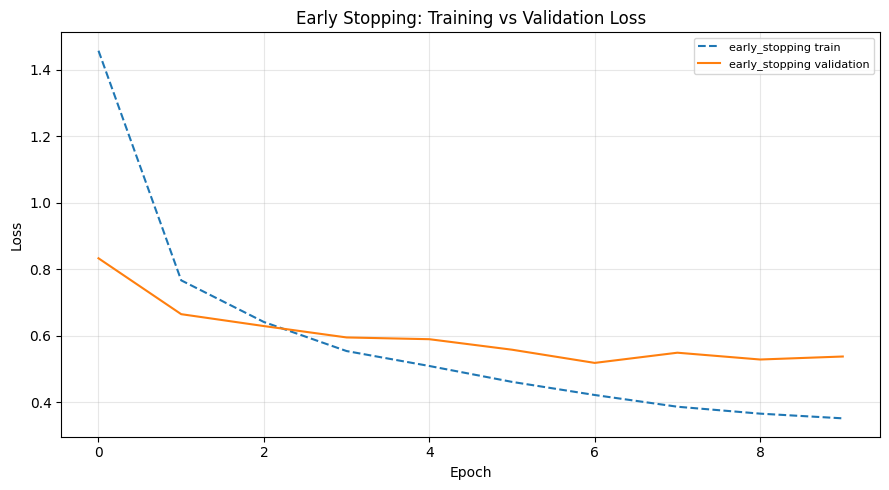


Experiment 4 completed.


,epochs_requested,epochs_ran,best_epoch,test_loss,test_accuracy
0,15,10,7,0.525119,0.822


In [12]:
early_stopping_results = run_early_stopping(
    epochs=15,
    train_limit=3000,
    test_limit=1000,
    seed=42
)

## Experiment 5 — Plain MLP vs Residual MLP

### Aim
To compare a plain multilayer perceptron with a residual multilayer perceptron under controlled training conditions.

### Theory
A plain MLP passes data through successive layers. A residual MLP adds a block's input to its transformed output, helping information and gradients flow through the network.

### Evaluation
Both models use the same Fashion-MNIST subset, Adam optimizer, learning rate, batch size, and epoch count. Test accuracy and test loss are compared.

In [13]:
def run_residual(
    epochs=6,
    train_limit=4000,
    test_limit=1000,
    seed=42
):
    train_loader, val_loader, test_loader = get_loaders(
        train_limit,
        test_limit,
        seed=seed
    )

    rows = []
    histories = {}

    for label, residual in [
        ("plain_mlp", False),
        ("residual_mlp", True)
    ]:
        print(f"\nRunning {label}")

        seed_everything(seed)

        model, history = train_model(
            SmallMLP(residual=residual),
            train_loader,
            val_loader,
            epochs,
            optimizer_name="adam",
            lr=0.001,
            schedule="constant",
            seed=seed
        )

        test_loss, test_acc = evaluate_test(
            model,
            test_loader
        )

        histories[label] = history

        rows.append({
            "model": label,
            "best_epoch": history["best_epoch"],
            "test_loss": test_loss,
            "test_accuracy": test_acc
        })

    plot_histories(
        histories,
        "Plain vs Residual MLP: Loss",
        "plain_vs_residual_loss.png",
        "loss"
    )

    df = pd.DataFrame(rows).sort_values(
        "test_accuracy",
        ascending=False
    )

    print("\nExperiment 5 completed.")
    display(df)

    return df


Running plain_mlp
Epoch 01/6 | train loss 1.2589 acc 0.560 | val loss 0.7816 acc 0.685 | lr 0.001
Epoch 02/6 | train loss 0.7138 acc 0.721 | val loss 0.6407 acc 0.753 | lr 0.001
Epoch 03/6 | train loss 0.5899 acc 0.764 | val loss 0.5991 acc 0.763 | lr 0.001
Epoch 04/6 | train loss 0.5160 acc 0.809 | val loss 0.5312 acc 0.803 | lr 0.001
Epoch 05/6 | train loss 0.4748 acc 0.822 | val loss 0.6257 acc 0.768 | lr 0.001
Epoch 06/6 | train loss 0.4542 acc 0.833 | val loss 0.5080 acc 0.823 | lr 0.001

Running residual_mlp
Epoch 01/6 | train loss 0.9858 acc 0.646 | val loss 0.7595 acc 0.725 | lr 0.001
Epoch 02/6 | train loss 0.6218 acc 0.759 | val loss 0.5646 acc 0.790 | lr 0.001
Epoch 03/6 | train loss 0.5013 acc 0.809 | val loss 0.5296 acc 0.805 | lr 0.001
Epoch 04/6 | train loss 0.4479 acc 0.834 | val loss 0.4989 acc 0.823 | lr 0.001
Epoch 05/6 | train loss 0.4158 acc 0.837 | val loss 0.5461 acc 0.807 | lr 0.001
Epoch 06/6 | train loss 0.3984 acc 0.847 | val loss 0.4898 acc 0.827 | lr 0.001

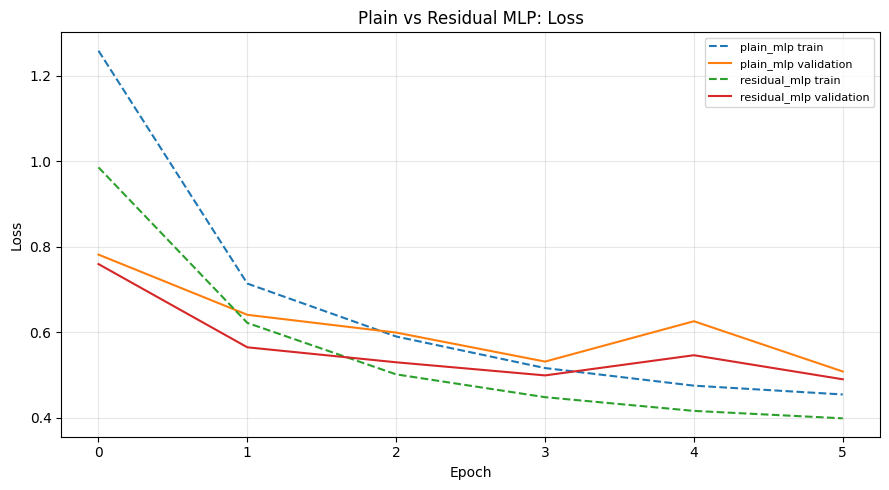


Experiment 5 completed.


,model,best_epoch,test_loss,test_accuracy
1,residual_mlp,6,0.490587,0.823
0,plain_mlp,6,0.516646,0.809


In [14]:
residual_results = run_residual(
    epochs=6,
    train_limit=4000,
    test_limit=1000,
    seed=42
)

In [19]:
print("EXPERIMENT 1: GRADIENT DESCENT")
display(gd_results)

print("\nEXPERIMENT 2: OPTIMIZERS")
display(optimizer_results)

print("\nEXPERIMENT 3: REGULARIZATION")
display(regularization_results)

print("\nEXPERIMENT 4: EARLY STOPPING")
display(early_stopping_results)

print("\nEXPERIMENT 5: PLAIN VS RESIDUAL MLP")
display(residual_results)

EXPERIMENT 1: GRADIENT DESCENT


,method,final_weight,final_bias,final_mse
0,batch,2.967382,1.468924,0.073761
1,stochastic,3.050401,1.404594,0.087840
2,mini-batch,2.975499,1.483569,0.073707



EXPERIMENT 2: OPTIMIZERS


,optimizer,lr_schedule,best_epoch,test_loss,test_accuracy
4,adam,constant,4,0.512812,0.817
5,adam,step,5,0.582743,0.778
0,sgd_momentum,constant,4,0.715513,0.719
2,rmsprop,constant,5,0.830421,0.683
3,rmsprop,step,5,0.876686,0.653
1,sgd_momentum,step,5,1.220402,0.581



EXPERIMENT 3: REGULARIZATION


,configuration,test_loss,test_accuracy,best_epoch,final_train_accuracy,final_validation_accuracy
1,dropout_0.3,0.528268,0.809,6,0.801961,0.784444
0,baseline,0.543540,0.806,6,0.825490,0.797778
2,L2_weight_decay,0.545825,0.801,6,0.823922,0.786667
3,data_augmentation,0.714623,0.717,5,0.702745,0.715556



EXPERIMENT 4: EARLY STOPPING


,epochs_requested,epochs_ran,best_epoch,test_loss,test_accuracy
0,15,10,7,0.525119,0.822



EXPERIMENT 5: PLAIN VS RESIDUAL MLP


,model,best_epoch,test_loss,test_accuracy
1,residual_mlp,6,0.490587,0.823
0,plain_mlp,6,0.516646,0.809


## Conclusion

The experiments demonstrated three gradient descent methods and compared momentum-based and adaptive optimizers with constant and scheduled learning rates.

Dropout, L2 regularization, and data augmentation were evaluated to investigate their effect on generalization. Early stopping demonstrated how validation loss can guide model selection and prevent unnecessary training.

Finally, the plain MLP and residual MLP were compared under similar training conditions. Their test performance showed how architecture can influence classification results.

The experiments used subsets of Fashion-MNIST and relatively short training runs to reduce computational cost. Therefore, the observations apply to the configurations tested and may differ with other datasets, hyperparameters, and training durations.